# Lab 2 — Faster R-CNN sur MNIST

Notebook Kaggle avec GPU T4. MNIST est un jeu de classification et ne contient pas de boîtes de détection. Pour appliquer Faster R-CNN, ce notebook transforme chaque image en un exemple de détection d’un seul objet : le chiffre est la classe, et sa boîte englobante est calculée depuis les pixels non blancs. Cette adaptation permet l’exercice, mais les scores ne sont pas directement équivalents aux métriques du CNN classifier.

Dans Kaggle, ajoutez `hojjatk/mnist-dataset` via **Add Input** et activez **Settings → Accelerator → GPU T4 x2**. Le notebook vérifie le nombre de GPU ; si Kaggle ne fournit qu’un GPU, l’entraînement s’arrête avec un message explicite.


In [1]:
from pathlib import Path
import os
import gzip, shutil, random, copy, time, json, subprocess, sys
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("GPU indisponible. Kaggle > Settings > Accelerator > GPU T4 x2")
NUM_GPUS = torch.cuda.device_count()
print("GPU détectés :", NUM_GPUS)
for i in range(NUM_GPUS):
    print(f"GPU {i} : {torch.cuda.get_device_name(i)}")
if NUM_GPUS < 2:
    print("Attention : ce notebook continuera sur un seul GPU. Sélectionnez l'option T4 x2 dans Kaggle.")
print("Datasets attachés :", [str(p) for p in Path('/kaggle/input').iterdir()])


GPU détectés : 2
GPU 0 : Tesla T4
GPU 1 : Tesla T4
Datasets attachés : ['/kaggle/input/datasets']


## Préparer les fichiers MNIST

Recherche des fichiers IDX dans `/kaggle/input`, compressés ou non.


In [2]:
required=['train-images-idx3-ubyte','train-labels-idx1-ubyte','t10k-images-idx3-ubyte','t10k-labels-idx1-ubyte']
files=[p for p in Path('/kaggle/input').rglob('*') if p.is_file()]
raw=Path('/kaggle/working/MNIST/raw'); raw.mkdir(parents=True,exist_ok=True)
for name in required:
    found=[p for p in files if p.name in (name,name+'.gz')]
    if not found: raise FileNotFoundError(f'{name} introuvable : vérifiez que le dataset MNIST est attaché.')
    src=found[0]; dst=raw/name
    if src.name.endswith('.gz'):
        with gzip.open(src,'rb') as fi, open(dst,'wb') as fo: shutil.copyfileobj(fi,fo)
    else: shutil.copy2(src,dst)
    print(src.name,'→',dst)


train-images-idx3-ubyte → /kaggle/working/MNIST/raw/train-images-idx3-ubyte
train-labels-idx1-ubyte → /kaggle/working/MNIST/raw/train-labels-idx1-ubyte
t10k-images-idx3-ubyte → /kaggle/working/MNIST/raw/t10k-images-idx3-ubyte
t10k-labels-idx1-ubyte → /kaggle/working/MNIST/raw/t10k-labels-idx1-ubyte


## Créer les exemples de détection

Les images sont agrandies à 96×96 pour convenir aux cartes de caractéristiques du détecteur. Les classes Faster R-CNN sont `1` à `10` ; `0` reste la classe de fond.


In [3]:
class MNISTDetection(Dataset):
    def __init__(self, train=True, indices=None):
        self.ds=datasets.MNIST('/kaggle/working',train=train,download=False)
        self.indices=list(range(len(self.ds))) if indices is None else list(indices)
        self.resize=transforms.Resize((64,64),antialias=True)
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        image,label=self.ds[self.indices[i]]
        gray=transforms.ToTensor()(image)
        rgb=self.resize(gray.repeat(3,1,1))
        ys,xs=torch.where(gray[0]>0.05)
        x1=max(0,int(xs.min())-1); y1=max(0,int(ys.min())-1)
        x2=min(28,int(xs.max())+2); y2=min(28,int(ys.max())+2)
        scale=64/28
        box=torch.tensor([[x1*scale,y1*scale,x2*scale,y2*scale]],dtype=torch.float32)
        target={'boxes':box,'labels':torch.tensor([int(label)+1],dtype=torch.int64),
                'image_id':torch.tensor([self.indices[i]],dtype=torch.int64),
                'area':torch.tensor([(x2-x1)*(y2-y1)*scale*scale],dtype=torch.float32),
                'iscrowd':torch.zeros((1,),dtype=torch.int64)}
        return rgb,target,int(label)

def collate_fn(batch):
    images,targets,digits=zip(*batch)
    return list(images),list(targets),torch.tensor(digits)

# Valeurs modifiables : commencez petit pour valider le pipeline, puis augmentez.
TRAIN_SIZE = 59000  
VAL_SIZE = 1000
BATCH_PER_GPU = 8
EPOCHS = 8
PATIENCE = 3

gen=torch.Generator().manual_seed(SEED)
perm=torch.randperm(60000,generator=gen).tolist()
train_idx=perm[VAL_SIZE:VAL_SIZE+TRAIN_SIZE]
val_idx=perm[:VAL_SIZE]
train_ds=MNISTDetection(train=True,indices=train_idx)
val_ds=MNISTDetection(train=True,indices=val_idx)
test_ds=MNISTDetection(train=False)
train_loader=DataLoader(train_ds,batch_size=8,shuffle=True,num_workers=2,pin_memory=True,collate_fn=collate_fn)
val_loader=DataLoader(val_ds,batch_size=8,shuffle=False,num_workers=2,pin_memory=True,collate_fn=collate_fn)
test_loader=DataLoader(test_ds,batch_size=8,shuffle=False,num_workers=2,pin_memory=True,collate_fn=collate_fn)
print(f'Train {len(train_ds)} | validation {len(val_ds)} | test {len(test_ds)}')


Train 59000 | validation 1000 | test 10000


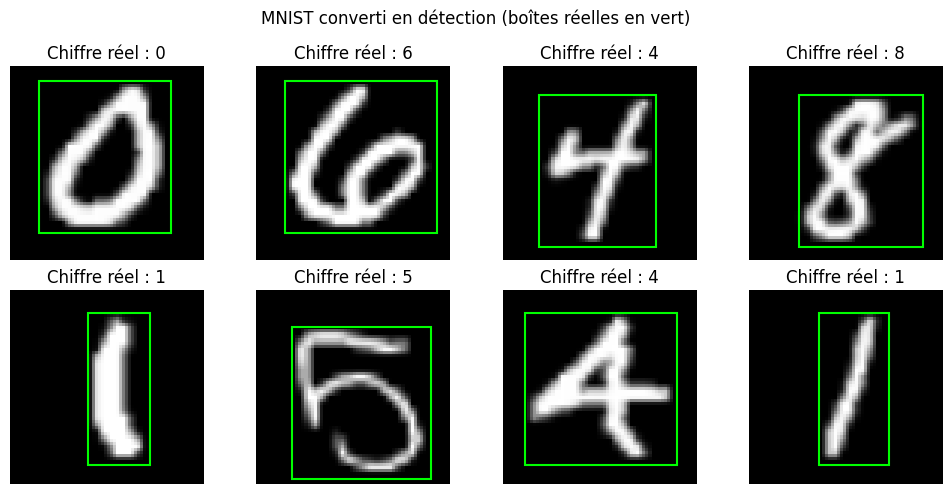

In [4]:
# Montrer un échantillon de 8 images et leur boîte réelle
images,targets,digits=next(iter(train_loader))
fig,axs=plt.subplots(2,4,figsize=(10,5))
for ax,img,t,digit in zip(axs.flat,images[:8],targets[:8],digits[:8]):
    ax.imshow(img[0].numpy(),cmap='gray')
    b=t['boxes'][0]
    ax.add_patch(plt.Rectangle((b[0],b[1]),b[2]-b[0],b[3]-b[1],fill=False,color='lime',linewidth=1.5))
    ax.set_title(f'Chiffre réel : {digit.item()}'); ax.axis('off')
plt.suptitle('MNIST converti en détection (boîtes réelles en vert)'); plt.tight_layout(); plt.show()


## Construire Faster R-CNN

Le modèle ResNet-50-FPN est initialisé sans poids pré-entraînés afin d’éviter tout téléchargement externe. Le détecteur apprend donc à la fois les caractéristiques et les régions d’intérêt sur MNIST.


In [5]:
NUM_CLASSES=11  # classe 0 = fond, classes 1..10 = chiffres 0..9
print(f"Faster R-CNN ResNet50-FPN | taille image 64x64 | batch global visé {BATCH_PER_GPU * max(NUM_GPUS, 1)}")
print("Entraînement distribué PyTorch DDP : un processus par GPU.")


Faster R-CNN ResNet50-FPN | taille image 64x64 | batch global visé 16
Entraînement distribué PyTorch DDP : un processus par GPU.


## Entraînement et validation

La loss Faster R-CNN est la somme des pertes de classification et de régression de boîtes (avec pertes RPN). Pour obtenir une accuracy comparable à une tâche de classification, on prend la classe de la détection ayant le score le plus élevé dans chaque image.


In [6]:
# PyTorch DistributedDataParallel : un processus sur chacun des deux GPU Kaggle.
# Le script autonome évite les problèmes de démarrage multiprocessing dans Jupyter.
worker_script = r"""
import os, json, copy, time, random
import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import Dataset, DataLoader, DistributedSampler
from torchvision import datasets, transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn

SEED=42
class MNISTDetection(Dataset):
    def __init__(self, train=True, indices=None):
        self.ds=datasets.MNIST('/kaggle/working',train=train,download=False)
        self.indices=list(range(len(self.ds))) if indices is None else list(indices)
        self.resize=transforms.Resize((64,64),antialias=True)
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        image,label=self.ds[self.indices[i]]
        gray=transforms.ToTensor()(image)
        rgb=self.resize(gray.repeat(3,1,1))
        ys,xs=torch.where(gray[0]>0.05)
        x1=max(0,int(xs.min())-1); y1=max(0,int(ys.min())-1)
        x2=min(28,int(xs.max())+2); y2=min(28,int(ys.max())+2)
        scale=64/28
        box=torch.tensor([[x1*scale,y1*scale,x2*scale,y2*scale]],dtype=torch.float32)
        target={'boxes':box,'labels':torch.tensor([int(label)+1],dtype=torch.int64),
                'image_id':torch.tensor([self.indices[i]],dtype=torch.int64),
                'area':torch.tensor([(x2-x1)*(y2-y1)*scale*scale],dtype=torch.float32),
                'iscrowd':torch.zeros((1,),dtype=torch.int64)}
        return rgb,target,int(label)
def collate_fn(batch):
    images,targets,digits=zip(*batch)
    return list(images),list(targets),torch.tensor(digits)
def move_targets(ts,device):
    return [{k:v.to(device) for k,v in t.items()} for t in ts]

def main():
    dist.init_process_group(backend='nccl')
    rank=int(os.environ['LOCAL_RANK']); world=int(os.environ['WORLD_SIZE'])
    torch.cuda.set_device(rank); device=torch.device('cuda',rank)
    random.seed(SEED+rank); np.random.seed(SEED+rank); torch.manual_seed(SEED+rank)
    train_size=int(os.environ['TRAIN_SIZE']); val_size=int(os.environ['VAL_SIZE'])
    epochs=int(os.environ['EPOCHS']); patience=int(os.environ['PATIENCE'])
    bpg=int(os.environ['BATCH_PER_GPU'])
    g=torch.Generator().manual_seed(SEED)
    perm=torch.randperm(60000,generator=g).tolist()
    train_idx=perm[val_size:val_size+train_size]; val_idx=perm[:val_size]
    train_ds=MNISTDetection(True,train_idx); val_ds=MNISTDetection(True,val_idx)
    sampler=DistributedSampler(train_ds,num_replicas=world,rank=rank,shuffle=True,seed=SEED,drop_last=True)
    train_loader=DataLoader(train_ds,batch_size=bpg,sampler=sampler,num_workers=2,pin_memory=True,collate_fn=collate_fn,persistent_workers=True)
    # Same validation partition on each process; rank 0 evaluates, then broadcasts loss.
    val_loader=DataLoader(val_ds,batch_size=bpg,shuffle=False,num_workers=2,pin_memory=True,collate_fn=collate_fn)
    model=fasterrcnn_resnet50_fpn(weights=None,weights_backbone=None,num_classes=11,min_size=64,max_size=64,
        rpn_pre_nms_top_n_train=300,rpn_post_nms_top_n_train=100,
        rpn_pre_nms_top_n_test=100,rpn_post_nms_top_n_test=50,box_detections_per_img=10).to(device)
    model=DDP(model,device_ids=[rank],output_device=rank,find_unused_parameters=False)
    optimizer=torch.optim.SGD(model.parameters(),lr=0.005,momentum=0.9,weight_decay=0.0005)
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=1)
    best=float('inf'); best_state=None; stale=0; history=[]; start=time.time()
    for epoch in range(1,epochs+1):
        model.train(); sampler.set_epoch(epoch); run_loss=0.; count=0
        for images,targets,_ in train_loader:
            images=[x.to(device,non_blocking=True) for x in images]
            targets=move_targets(targets,device)
            optimizer.zero_grad(set_to_none=True)
            losses=model(images,targets); loss=sum(losses.values())
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.0); optimizer.step()
            run_loss+=loss.item()*len(images); count+=len(images)
        # Average epoch train loss across ranks.
        stats=torch.tensor([run_loss,count],device=device,dtype=torch.float64)
        dist.all_reduce(stats,op=dist.ReduceOp.SUM)
        train_loss=(stats[0]/stats[1]).item()
        # Validation only on rank 0, broadcast result so all ranks stop together.
        val_tensor=torch.zeros(1,device=device)
        if rank==0:
            model.module.train()
            vtotal=0.; vn=0
            with torch.no_grad():
                for images,targets,_ in val_loader:
                    images=[x.to(device,non_blocking=True) for x in images]
                    losses=model.module(images,move_targets(targets,device))
                    vtotal+=sum(losses.values()).item()*len(images); vn+=len(images)
            val_tensor[0]=vtotal/vn
        dist.broadcast(val_tensor,src=0); val_loss=val_tensor.item(); scheduler.step(val_loss)
        if rank==0:
            history.append({'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss})
            print(f'Epoch {epoch:02d}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | elapsed {(time.time()-start)/60:.1f} min',flush=True)
            if val_loss<best:
                best=val_loss; best_state=copy.deepcopy(model.module.state_dict()); stale=0
                torch.save(best_state,'/kaggle/working/mnist_faster_rcnn_best.pth')
            else: stale+=1
            if stale>=patience: print('Early stopping.',flush=True)
        stop=torch.tensor([1 if rank==0 and stale>=patience else 0],device=device)
        dist.broadcast(stop,src=0)
        if stop.item(): break
    if rank==0:
        with open('/kaggle/working/mnist_faster_rcnn_history.json','w') as f: json.dump(history,f)
        print(f'Temps total entraînement : {(time.time()-start)/60:.1f} minutes',flush=True)
    dist.barrier(); dist.destroy_process_group()
if __name__=='__main__': main()
"""
script_path='/kaggle/working/train_faster_rcnn_ddp.py'
with open(script_path,'w',encoding='utf-8') as f: f.write(worker_script)
if NUM_GPUS < 2:
    raise RuntimeError('Pour cette version, choisissez GPU T4 x2 dans Kaggle > Settings > Accelerator.')
env=os.environ.copy()
env.update({'TRAIN_SIZE':str(TRAIN_SIZE),'VAL_SIZE':str(VAL_SIZE),'EPOCHS':str(EPOCHS),
            'PATIENCE':str(PATIENCE),'BATCH_PER_GPU':str(BATCH_PER_GPU)})
cmd=[sys.executable,'-m','torch.distributed.run','--standalone','--nnodes=1','--nproc_per_node=2',script_path]
print('Lancement DDP sur les 2 GPU T4 ...')
subprocess.run(cmd,env=env,check=True)
with open('/kaggle/working/mnist_faster_rcnn_history.json',encoding='utf-8') as f:
    history=json.load(f)
training_seconds=None  # durée détaillée affichée par le script DDP
# Charger le modèle entraîné pour les cellules d'évaluation/affichage ci-dessous.
device=torch.device('cuda:0')
model=fasterrcnn_resnet50_fpn(weights=None,weights_backbone=None,num_classes=11,min_size=64,max_size=64,
    rpn_pre_nms_top_n_train=300,rpn_post_nms_top_n_train=100,
    rpn_pre_nms_top_n_test=100,rpn_post_nms_top_n_test=50,box_detections_per_img=10).to(device)
model.load_state_dict(torch.load('/kaggle/working/mnist_faster_rcnn_best.pth',map_location=device))
model.eval()


Lancement DDP sur les 2 GPU T4 ...



*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************


Epoch 01/8 | train loss 0.3219 | val loss 0.1679 | elapsed 9.8 min
Epoch 02/8 | train loss 0.1335 | val loss 0.1221 | elapsed 19.5 min
Epoch 03/8 | train loss 0.0923 | val loss 0.0810 | elapsed 29.1 min
Epoch 04/8 | train loss 0.0718 | val loss 0.0792 | elapsed 38.8 min
Epoch 05/8 | train loss 0.0594 | val loss 0.0653 | elapsed 48.5 min
Epoch 06/8 | train loss 0.0510 | val loss 0.0536 | elapsed 58.3 min
Epoch 07/8 | train loss 0.0480 | val loss 0.0534 | elapsed 69.0 min
Epoch 08/8 | train loss 0.0444 | val loss 0.0655 | elapsed 79.9 min
Temps total entraînement : 79.9 minutes


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(64,), max_size=64, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          

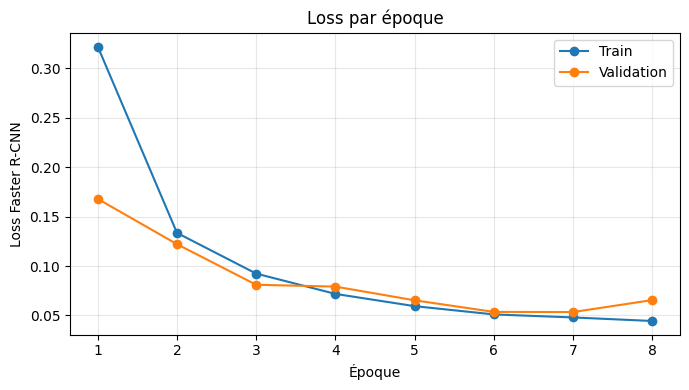

In [7]:
# Courbes de loss train/validation
epochs=[r['epoch'] for r in history]
plt.figure(figsize=(7,4))
plt.plot(epochs,[r['train_loss'] for r in history],marker='o',label='Train')
plt.plot(epochs,[r['val_loss'] for r in history],marker='o',label='Validation')
plt.xlabel('Époque'); plt.ylabel('Loss Faster R-CNN'); plt.title('Loss par époque')
plt.grid(True,alpha=.3); plt.legend(); plt.tight_layout(); plt.show()


## Évaluer sur le test

La loss test est calculée en mode entraînement sans mise à jour des poids. L’accuracy et le F1 macro utilisent la classe de la détection au score maximal. La qualité des boîtes nécessiterait en plus une mesure de détection telle que mAP.


In [8]:
from sklearn.metrics import accuracy_score,f1_score,classification_report

@torch.no_grad()
def evaluate_test(loader):
    model.eval(); preds=[]; labels=[]
    for images,targets,digits in loader:
        outputs=model([im.to(device,non_blocking=True) for im in images])
        for out,digit in zip(outputs,digits):
            if len(out['labels'])==0: pred=0
            else: pred=int(out['labels'][out['scores'].argmax()].item())-1
            preds.append(pred); labels.append(int(digit))
    return labels,preds

# L’évaluation en mode détection rapporte accuracy/F1 pour les classes prédites.
y_true,y_pred=evaluate_test(test_loader)
print(f'Test accuracy       : {accuracy_score(y_true,y_pred):.4f}')
print(f'Test F1 macro       : {f1_score(y_true,y_pred,average="macro"):.4f}')
print('Temps d’entraînement détaillé affiché dans la cellule DDP ci-dessus.')
print('\nRapport par chiffre :')
print(classification_report(y_true,y_pred,digits=4,zero_division=0))


Test accuracy       : 0.9922
Test F1 macro       : 0.9921
Temps d’entraînement détaillé affiché dans la cellule DDP ci-dessus.

Rapport par chiffre :
              precision    recall  f1-score   support

           0     0.9909    0.9959    0.9934       980
           1     0.9921    1.0000    0.9961      1135
           2     0.9971    0.9932    0.9951      1032
           3     0.9950    0.9921    0.9936      1010
           4     0.9929    0.9959    0.9944       982
           5     0.9921    0.9877    0.9899       892
           6     0.9989    0.9812    0.9900       958
           7     0.9884    0.9922    0.9903      1028
           8     0.9838    0.9949    0.9893       974
           9     0.9910    0.9871    0.9891      1009

    accuracy                         0.9922     10000
   macro avg     0.9922    0.9920    0.9921     10000
weighted avg     0.9922    0.9922    0.9922     10000



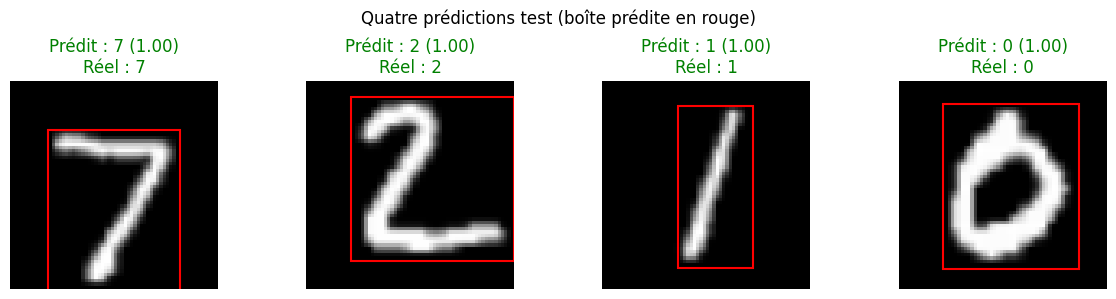

Modèle sauvegardé : /kaggle/working/mnist_faster_rcnn_best.pth


In [9]:
# Afficher quatre images test avec boîte prédite, chiffre prédit et chiffre réel
images,targets,digits=next(iter(test_loader))
with torch.no_grad():
    outputs=model([im.to(device) for im in images[:4]])
fig,axs=plt.subplots(1,4,figsize=(12,3))
for ax,img,target,digit,out in zip(axs,images[:4],targets[:4],digits[:4],outputs):
    ax.imshow(img[0].numpy(),cmap='gray')
    gt=int(digit.item())
    if len(out['labels']):
        k=int(out['scores'].argmax()); pred=int(out['labels'][k].item())-1
        box=out['boxes'][k].cpu(); score=float(out['scores'][k].cpu())
        ax.add_patch(plt.Rectangle((box[0],box[1]),box[2]-box[0],box[3]-box[1],fill=False,color='red',linewidth=1.5))
        title=f'Prédit : {pred} ({score:.2f})\nRéel : {gt}'
    else:
        title=f'Aucune détection\nRéel : {gt}'
    ax.set_title(title,color='green' if len(out['labels']) and pred==gt else 'red'); ax.axis('off')
plt.suptitle('Quatre prédictions test (boîte prédite en rouge)'); plt.tight_layout(); plt.show()

torch.save(model.state_dict(),'/kaggle/working/mnist_faster_rcnn_best.pth')
print('Modèle sauvegardé : /kaggle/working/mnist_faster_rcnn_best.pth')


## Remarques pour le compte rendu

- Faster R-CNN renvoie une loss de détection composée de plusieurs termes ; elle n’a pas la même définition que la cross-entropy du CNN classifier.
- L’accuracy/F1 ci-dessus sont une adaptation en prenant la meilleure détection de chaque image. Elles aident à comparer la reconnaissance du chiffre, mais ne mesurent pas la précision de localisation.
- Pour comparer la détection au sens strict, rapporter aussi mAP avec une implémentation de métriques de détection et décrire la règle de boîte utilisée.
- La version utilise DDP si Kaggle propose réellement deux T4. TRAIN_SIZE=6000, VAL_SIZE=1000 et des images 64×64 donnent un démarrage raisonnable ; augmentez ces valeurs après avoir vérifié le temps par époque. L’early stopping suit la validation.
